# E-commerce Return Risk Predictor

## 1. Problem Definition
**Business problem:** Online fashion retailers lose money on returned orders (shipping, handling, resale discounts). If risky orders can be flagged at checkout, the retailer can act early, for example with a size-guide prompt or by discouraging size bracketing.

**Target:** `return_risk_label` (1 = returned, 0 = kept), so this is binary classification.

**Features (12):** numerical: `cart_value_usd`, `past_return_rate`, `delivery_days_taken`, `discount_pct_applied`; categorical: `product_category`, `fit_review_sentiment`, `size_bracketing_flag`, `newsletter_subscriber`, `browser_used`, `checkout_device`, `packaging_color`, `loyalty_card_color`.

**How ML helps:** a model learns from 2,993 past orders which combinations of order and customer characteristics lead to returns, and gives each new order a return-risk prediction that can trigger a preventive action.

In [117]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_selection import f_classif, SelectFpr

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

In [118]:
ecom_data = pd.read_csv('./ecommerce_return_classification.csv')

In [119]:
ecom_data.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [120]:
ecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


In [121]:
numerical_features = [
    "cart_value_usd",
    "past_return_rate",
    "delivery_days_taken",
    "discount_pct_applied",
]

categorical_features = [
    "product_category",
    "fit_review_sentiment",
    "browser_used",
    "checkout_device",
    "packaging_color",
    "loyalty_card_color",
    "size_bracketing_flag",
    "newsletter_subscriber",
]

print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['cart_value_usd', 'past_return_rate', 'delivery_days_taken', 'discount_pct_applied']
Categorical Features: ['product_category', 'fit_review_sentiment', 'browser_used', 'checkout_device', 'packaging_color', 'loyalty_card_color', 'size_bracketing_flag', 'newsletter_subscriber']


In [122]:
ecom_data[numerical_features].describe()

,cart_value_usd,past_return_rate,delivery_days_taken,discount_pct_applied
count,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.750301,0.284024,5.974273,23.879051
std,121.394772,0.159998,3.188330,17.263143
min,25.010000,0.005000,1.000000,0.000000
25%,135.560000,0.157000,3.000000,10.000000
50%,238.740000,0.265000,6.000000,20.000000
75%,343.920000,0.386000,9.000000,40.000000
max,449.860000,0.884000,11.000000,50.000000


In [123]:
ecom_data.loc[ecom_data.duplicated()]

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label


In [124]:
ecom_data.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [125]:
rows = []

for feature in numerical_features:
    Q1 = ecom_data[feature].quantile(0.25)
    Q3 = ecom_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    below = (ecom_data[feature] < lower_bound).sum()
    above = (ecom_data[feature] > upper_bound).sum()
    total = below + above

    rows.append({
        'feature': feature,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'below_lower': below,
        'above_upper': above,
        'outlier_count': total,
        'outlier_pct': round(total / ecom_data[feature].notna().sum() * 100, 2),
    })

outlier_summary = (
    pd.DataFrame(rows)
    .set_index('feature')
    .sort_values('outlier_count', ascending=False)
)

display(outlier_summary)

,lower_bound,upper_bound,below_lower,above_upper,outlier_count,outlier_pct
feature,,,,,,
past_return_rate,-0.1865,0.7295,0,25,25,0.84
cart_value_usd,-176.9800,656.4600,0,0,0,0.00
delivery_days_taken,-6.0000,18.0000,0,0,0,0.00
discount_pct_applied,-35.0000,85.0000,0,0,0,0.00


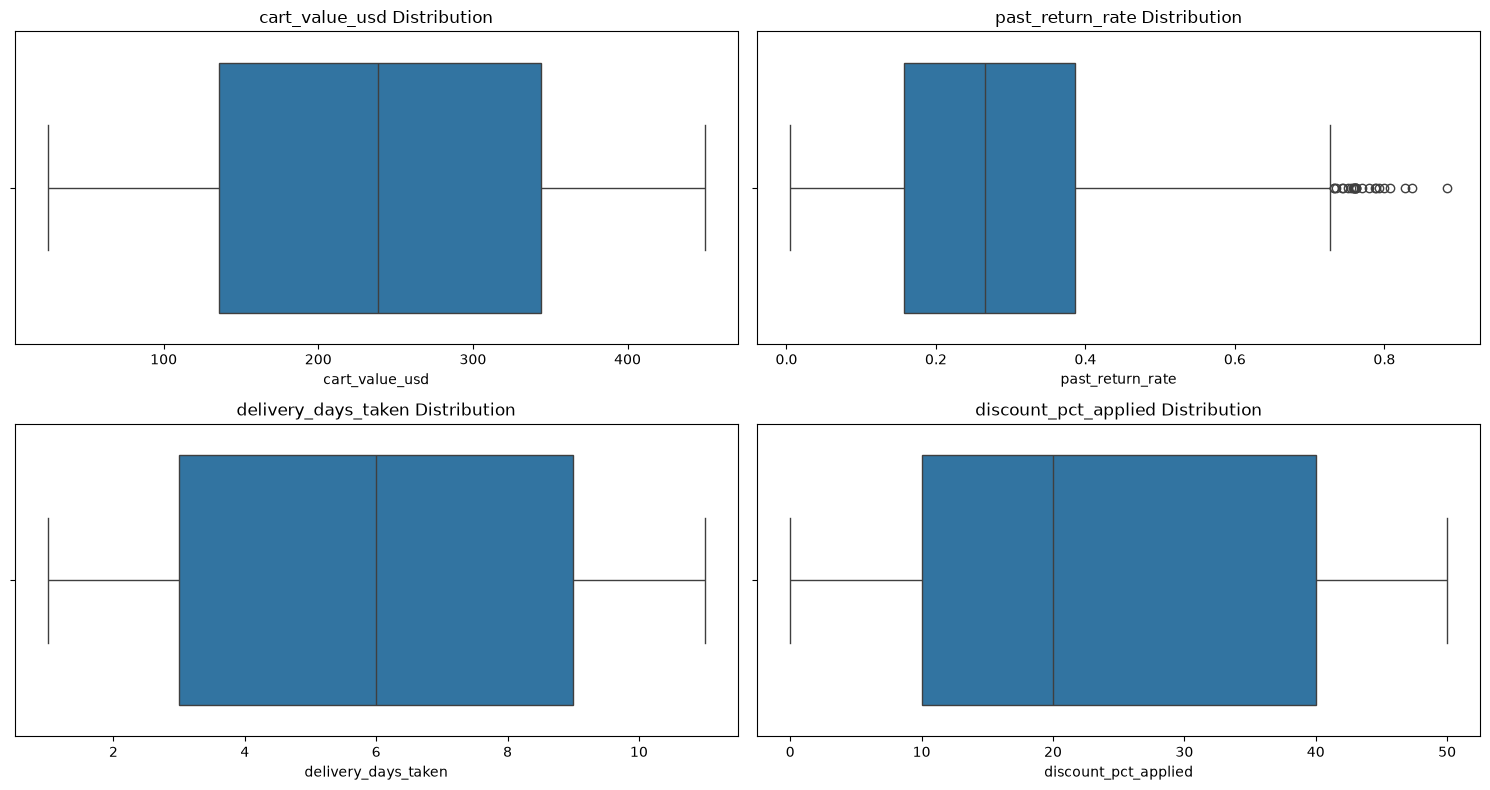

,count,mean
product_category,,
Accessories,589,0.374
Casual-Tops,1015,0.592
Footwear,752,0.763
Formal-Eveningwear,637,0.843


,count,mean
fit_review_sentiment,,
Inconsistent-Sizing,573,0.871
Runs-Slightly-Small,922,0.772
True-to-Size,1498,0.481


,count,mean
browser_used,,
Chrome,750,0.647
Edge,745,0.647
Firefox,752,0.650
Safari,746,0.638


,count,mean
checkout_device,,
Android-App,1036,0.647
Desktop-Web,989,0.644
iOS-App,968,0.646


,count,mean
packaging_color,,
Branded-Teal,1001,0.652
Kraft-Brown,1010,0.639
Minimal-White,982,0.646


,count,mean
loyalty_card_color,,
Gold,970,0.646
Platinum,1023,0.635
Silver,1000,0.655


,count,mean
size_bracketing_flag,,
0,1933,0.514
1,1060,0.885


,count,mean
newsletter_subscriber,,
0,1486,0.647
1,1507,0.644


In [126]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
  sns.boxplot(data=ecom_data, x=feature, ax=axes[i])
  axes[i].set_title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

for feature in categorical_features:
    display(ecom_data.groupby(feature)['return_risk_label'].agg(['count', 'mean']).round(3))

In [127]:
ecom_data['return_risk_label'].value_counts()

return_risk_label
1    1932
0    1061
Name: count, dtype: int64

In [128]:
ecom_data[numerical_features].skew()

cart_value_usd         -0.015701
past_return_rate        0.625869
delivery_days_taken     0.027763
discount_pct_applied    0.068640
dtype: float64

# Insights

*   From the describe table, `cart_value_usd`, `discount_pct_applied` and `delivery_days_taken` are mostly symmetric while the `past_return_rate` has a right skew due to outliers.
*   `cart_value_usd`, `delivery_days_taken` and `discount_pct_applied` have no outliers while `past_return_rate` has 0.84% outliers which needs to be handled via preprocessing.
*   There are no duplicated and missing values in the data.


In [129]:
ecom_data.drop_duplicates(inplace=True)
ecom_data.dropna(inplace=True)
ecom_data.reset_index(inplace=True, drop=True)

In [130]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

In [131]:
X = ecom_data.drop(columns=['return_risk_label'])
y = ecom_data['return_risk_label']

In [132]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [133]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (2095, 12)
Validation: (449, 12)
Test: (449, 12)


In [134]:
baseline = DummyClassifier(random_state=42, strategy='most_frequent').fit(X_train, y_train)
pred = baseline.predict(X_test)
print(accuracy_score(y_test, pred), f1_score(y_test, pred))

0.6458797327394209 0.7848443843031123


### Model Selection Reasoning

* **Dataset size:** about 3,000 orders, so this falls in the **small dataset** branch (under 5,000 rows).
* **Is the relationship mostly linear?** Mostly yes. Return rate changes clearly with product category, fit sentiment and size bracketing, and the numeric features are roughly symmetric. The guideline says to start with simpler, more interpretable models and avoid complex ones that overfit.
* **Are outliers important?** Slightly. `past_return_rate` has 0.84% outliers, which I kept as valid values. The guideline suggests robust models such as Random Forest for this case.
* **Additional considerations:** the retailer needs to understand why an order is flagged (interpretability) and the flag must be fast at checkout (speed). Both favour simple models. Classification is evaluated with F1 and ROC-AUC, as the guideline's final step recommends, because the classes are imbalanced (64.5% returned).

**Chosen models:**

1. **Logistic Regression** (Linear and Regularized family): the guideline's first choice for a mostly linear problem. It is fast, interpretable and outputs return probabilities. L1/L2 regularisation guards against overfitting.
2. **Support Vector Machine** (Support Vector family): listed in the same branch, "if complex boundary". It checks whether a more flexible, non-linear boundary improves on Logistic Regression.
3. **Random Forest** (Tree-Based family): listed for both the non-linear and the outlier-robust branches. It captures interactions (for example size bracketing combined with product category) without extra feature engineering, so it tests whether the data hold non-linear patterns the linear models miss.


In [135]:
pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor),
                               ('smote', SMOTE(random_state=42)),
                               ('feature_selection', SelectFpr(f_classif, alpha=0.05)),
                               ('classifier', LogisticRegression(random_state=42))])

param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["liblinear"],
}

grid_search_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, scoring={"f1": "f1", "roc_auc": "roc_auc"}, refit='f1', n_jobs=-1, verbose=1)
grid_search_lr.fit(X_train, y_train)

print(f"Best parameters: {grid_search_lr.best_params_}")
print(f"Best CV F1: {grid_search_lr.best_score_:.3f}")
print(f"CV ROC-AUC of that model: {grid_search_lr.cv_results_['mean_test_roc_auc'][grid_search_lr.best_index_]:.3f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'classifier__C': 100, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best CV F1: 0.950
CV ROC-AUC of that model: 0.985


c:\Users\buzz\Desktop\ml-portfolio-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\buzz\Desktop\ml-portfolio-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [136]:
pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor),
                               ('smote', SMOTE(random_state=42)),
                               ('feature_selection', SelectFpr(f_classif, alpha=0.05)),
                               ('classifier', RandomForestClassifier(random_state=42, n_jobs=1))])

param_grid_rf = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [1, 2, 4],
}

grid_search_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring={"f1": "f1", "roc_auc": "roc_auc"}, refit='f1', n_jobs=-1)
grid_search_rf.fit(X_train, y_train)

print(f"Best parameters: {grid_search_rf.best_params_}")
print(f"Best CV F1: {grid_search_rf.best_score_:.3f}")
print(f"CV ROC-AUC of that model: {grid_search_rf.cv_results_['mean_test_roc_auc'][grid_search_rf.best_index_]:.3f}")

Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Best CV F1: 0.925
CV ROC-AUC of that model: 0.967


In [137]:
pipeline_svm = Pipeline(steps=[('preprocessor', preprocessor),
                               ('smote', SMOTE(random_state=42)),
                               ('feature_selection', SelectFpr(f_classif, alpha=0.05)),
                               ('classifier', SVC(random_state=42))])

param_grid_svm = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__kernel": ["rbf", "linear"],
    "classifier__gamma": ["scale", 0.01, 0.1],   
}

grid_search_svm = GridSearchCV(pipeline_svm, param_grid_svm, cv=5, scoring={"f1": "f1", "roc_auc": "roc_auc"}, refit='f1', n_jobs=-1, verbose=1)
grid_search_svm.fit(X_train, y_train)

print(f"Best parameters: {grid_search_svm.best_params_}")
print(f"Best CV F1: {grid_search_svm.best_score_:.3f}")
print(f"CV ROC-AUC of that model: {grid_search_svm.cv_results_['mean_test_roc_auc'][grid_search_svm.best_index_]:.3f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best CV F1: 0.948
CV ROC-AUC of that model: 0.985


In [138]:
best_models = {
    'LogisticRegression': {'model': grid_search_lr.best_estimator_, 'cv_f1': grid_search_lr.best_score_},
    'RandomForest':       {'model': grid_search_rf.best_estimator_, 'cv_f1': grid_search_rf.best_score_},
    'SVM':                {'model': grid_search_svm.best_estimator_, 'cv_f1': grid_search_svm.best_score_},
}

best_model_name = max(best_models, key=lambda k: best_models[k]['cv_f1'])
best_model_info = best_models[best_model_name]

print(f"The best model is {best_model_name} with a CV F1 of {best_model_info['cv_f1']:.3f}")

The best model is LogisticRegression with a CV F1 of 0.950


,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,
LogisticRegression,0.950,0.927,0.957,0.928,0.942,0.986
RandomForest,0.925,0.891,0.926,0.903,0.914,0.968
SVM,0.948,0.927,0.961,0.924,0.942,0.986


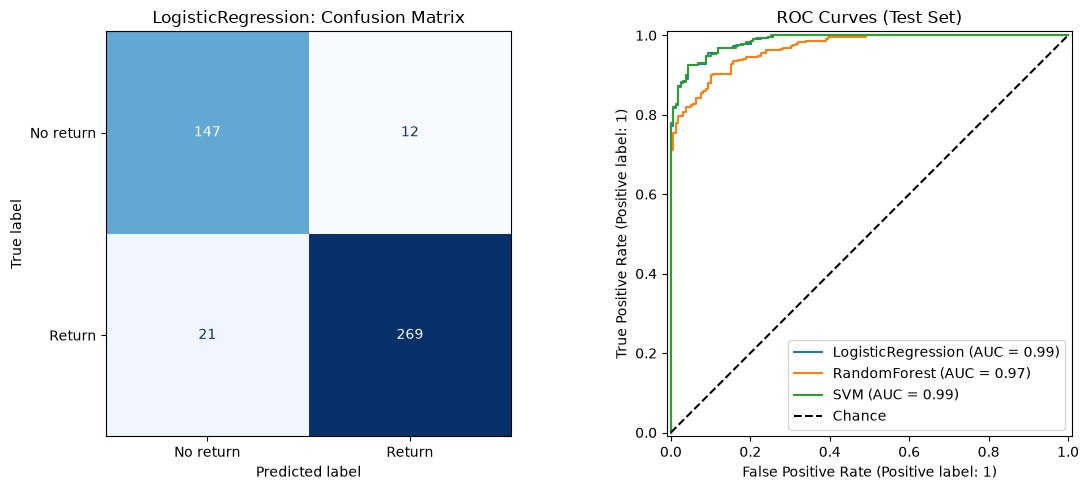

In [139]:
def get_scores(model, X):
    """Continuous scores for ROC-AUC (SVC has no predict_proba by default)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

results = []
for name, info in best_models.items():
    y_pred = info['model'].predict(X_test)
    y_score = get_scores(info['model'], X_test)
    results.append({
        'model': name,
        'cv_f1': info['cv_f1'],
        'test_accuracy': accuracy_score(y_test, y_pred),
        'test_precision': precision_score(y_test, y_pred),
        'test_recall': recall_score(y_test, y_pred),
        'test_f1': f1_score(y_test, y_pred),
        'test_roc_auc': roc_auc_score(y_test, y_score),
    })

results_df = pd.DataFrame(results).set_index('model').round(3)
display(results_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

best_pred = best_model_info['model'].predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred),
                       display_labels=['No return', 'Return']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'{best_model_name}: Confusion Matrix')

for name, info in best_models.items():
    RocCurveDisplay.from_predictions(y_test, get_scores(info['model'], X_test), name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Chance')
axes[1].set_title('ROC Curves (Test Set)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [140]:
joblib.dump(best_model_info['model'], 'ecommerce_returns_model.pkl')

['ecommerce_returns_model.pkl']

## Conclusion

* **Baseline:** always predicting "returned" gives accuracy 0.646, F1 0.785 and ROC-AUC 0.500. Every tuned model is far above this.
* **Final model:** Logistic Regression. It has the best cross-validated F1 (0.950) and ties with the SVM on the test set, whose tuned kernel ended up linear, so it is effectively the same model. Logistic Regression is the better choice because it is simpler, easier to explain and gives a return probability for each order. Random Forest was weakest.